# Задание 2.5*
## Уравнение окружности в комплексной записи

### Условие:
Пусть $A$ и $C$ — действительные, $B$ — комплексная постоянные, $AC<|B|^2$. Покажите, что уравнение
$$
A|z|^2+\overline{B}z+B\overline{z}+C=0,\qquad (A>0),
$$
является уравнением окружности, и найдите её центр и радиус.

### Решение:
Запишем $z=x+iy$, $B=b_1+ib_2$ ($b_1,b_2\in\mathbb R$). Тогда $|z|^2=x^2+y^2$, а
$$
\overline Bz+B\overline z=2\operatorname{Re}(\overline Bz)=2\operatorname{Re}\bigl((b_1-ib_2)(x+iy)\bigr)=2(b_1x+b_2y).
$$
Уравнение принимает вид $A(x^2+y^2)+2b_1x+2b_2y+C=0$. Так как $A>0$, поделим на $A$ и выделим полные квадраты:
$$
\Bigl(x+\frac{b_1}{A}\Bigr)^2+\Bigl(y+\frac{b_2}{A}\Bigr)^2=\frac{b_1^2+b_2^2}{A^2}-\frac CA=\frac{|B|^2-AC}{A^2}.
$$
По условию $AC<|B|^2$ (оба числа действительные, сравнение корректно), поэтому правая часть строго положительна. Значит, это окружность с центром $(-b_1/A,\,-b_2/A)$, то есть $z_0=-\dfrac BA$, и радиусом
$$
R=\frac{\sqrt{|B|^2-AC}}{A}.
$$
(При $AC=|B|^2$ получилась бы одна точка, при $AC>|B|^2$ — пустое множество.)

### Проверка в `sympy`: левая часть уравнения совпадает с $A\,[(x-x_0)^2+(y-y_0)^2-R^2]$

In [1]:
from sympy import symbols, expand, simplify, I, conjugate, sqrt

x, y, A, C, b1, b2 = symbols('x y A C b1 b2', real=True)
B = b1 + I*b2
z = x + I*y

lhs = expand(A*z*conjugate(z) + conjugate(B)*z + B*conjugate(z) + C)
print('Левая часть в координатах:', simplify(lhs))

x0, y0 = -b1/A, -b2/A
R2 = (b1**2 + b2**2 - A*C)/A**2
circle = expand(A*((x - x0)**2 + (y - y0)**2 - R2))
print('A[(x-x0)^2 + (y-y0)^2 - R^2] =', simplify(circle))
print('тождество выполнено:', simplify(lhs - circle) == 0)

Левая часть в координатах: A*x**2 + A*y**2 + C + 2*b1*x + 2*b2*y
A[(x-x0)^2 + (y-y0)^2 - R^2] = A*x**2 + A*y**2 + C + 2*b1*x + 2*b2*y
тождество выполнено: True


### Числовой пример: $A=2$, $B=1+2i$, $C=1$ (здесь $AC=2<|B|^2=5$)

центр z0 = (-0.5-1j),  радиус R = 0.866025
левая часть в точках найденной окружности: [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -0.+0.j  0.+0.j  0.+0.j  0.+0.j]


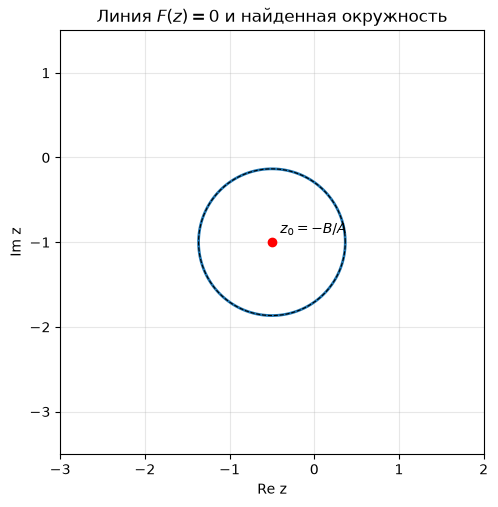

In [2]:
import numpy as np
import matplotlib.pyplot as plt

A_, B_, C_ = 2.0, 1 + 2j, 1.0
z0 = -B_/A_
R = np.sqrt(abs(B_)**2 - A_*C_)/A_
print(f'центр z0 = {z0},  радиус R = {R:.6f}')

phi = np.linspace(0, 2*np.pi, 9)
pts = z0 + R*np.exp(1j*phi)
vals = A_*abs(pts)**2 + np.conj(B_)*pts + B_*np.conj(pts) + C_
print('левая часть в точках найденной окружности:', np.round(vals, 12))

# график: нулевая линия уровня функции левой части
xs = np.linspace(-3, 2, 600); ys = np.linspace(-3.5, 1.5, 600)
X, Y = np.meshgrid(xs, ys); Z = X + 1j*Y
F = (A_*abs(Z)**2 + np.conj(B_)*Z + B_*np.conj(Z) + C_).real
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.contour(X, Y, F, levels=[0], colors='tab:blue', linewidths=2)
ax.plot(z0.real, z0.imag, 'ro'); ax.annotate('$z_0=-B/A$', (z0.real, z0.imag), xytext=(6, 6), textcoords='offset points')
t = np.linspace(0, 2*np.pi, 300)
ax.plot(z0.real + R*np.cos(t), z0.imag + R*np.sin(t), 'k--', lw=0.8)
ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlabel('Re z'); ax.set_ylabel('Im z')
ax.set_title('Линия $F(z)=0$ и найденная окружность')
plt.show()

### Ответ:

Уравнение определяет окружность
$$
\Bigl|z+\frac BA\Bigr|=\frac{\sqrt{|B|^2-AC}}{A},
$$
центр $z_0=-\dfrac BA$, радиус $R=\dfrac{\sqrt{|B|^2-AC}}{A}$.